In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import minimize
from PIL import Image

from pathlib import Path
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize
from PIL import Image

In [2]:
image_path = Path(r'C:\Users\asus\Documents\semester 5\CV\as2\a2images\a2images')
output_path = Path('results')
output_path.mkdir(exist_ok=True)
assert image_path.is_dir(), 'Check image_path.'
np.random.seed(0)
cv.setRNGSeed(0)
print('GitHub: https://github.com/Upani-Gunathunga')

GitHub: https://github.com/Upani-Gunathunga


Question 1

In [3]:
#en3160_assignment_02.pdf
im = cv.imread(str(image_path / 'the_berry_farms_sunflower_field.jpeg'), cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
f = gray.astype(np.float32) / 255.0
h, w = f.shape
sigmas = np.arange(1, 25, 1) #1 o 24
scale_space = np.empty((h, w, len(sigmas)), dtype=np.float32)



In [4]:
for i, sigma in enumerate(sigmas):
    blurred = cv.GaussianBlur(f, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma))
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=1)
    scale_space[:, :, i] = sigma**2 * laplacian #scale normalizing

response = scale_space**2
threshold = 0.08 * response.max()


In [5]:
#---------algorithm based on lec slides--------------
# Position and scale maxima
local_max = maximum_filter(response, size=(3, 3, 24)) #each pixel which sigma gives max


mask = (response == local_max) & (response > threshold)

mask = mask & (scale_space > 0) ##dark centers surrounds by brightpixels are identified
#in this sign convention




In [6]:
y_indices, x_indices, scale_indices = np.where(mask)
circles = []
for y, x, i in zip(y_indices, x_indices, scale_indices):
    radius = np.sqrt(2) * sigmas[i]
    if x - radius < 0 or x + radius >= w:
        continue
    if y - radius < 0 or y + radius >= h:
        continue
    circles.append([x, y, radius, sigmas[i], response[y, x, i]])
#--------------------------------------------------------
assert len(circles) > 0, 'No circles found. change the threshold.'
circles = np.array(circles)
order = np.argsort(circles[:, 2])[::-1]
circles = circles[order]  #descending order of radius


In [7]:
output = im.copy()
for x, y, radius, sigma, value in circles:
    centre = (int(x), int(y))
    cv.circle(output, centre, int(round(radius)), (255, 0, 255), 1)

print('Detected dark blobs:', len(circles))
cv.imwrite(str(output_path / 'q1_circles.png'), output)

#final sigma was not multiplied by 4 as circles are also drawn on shrinked image


Detected dark blobs: 550


True

In [8]:
output

array([[[208, 135,  91],
        [210, 137,  93],
        [207, 134,  90],
        ...,
        [199, 117,  62],
        [200, 118,  63],
        [198, 116,  61]],

       [[208, 135,  91],
        [210, 137,  93],
        [207, 134,  90],
        ...,
        [202, 120,  65],
        [200, 118,  63],
        [198, 116,  61]],

       [[206, 133,  89],
        [212, 139,  95],
        [209, 136,  92],
        ...,
        [204, 122,  67],
        [198, 116,  61],
        [198, 116,  61]],

       ...,

       [[ 19,  47,  34],
        [ 16,  44,  31],
        [ 17,  45,  32],
        ...,
        [ 15,  70,  53],
        [ 13,  68,  51],
        [  9,  64,  47]],

       [[ 17,  45,  32],
        [ 17,  45,  32],
        [ 16,  44,  31],
        ...,
        [ 17,  72,  55],
        [ 13,  68,  51],
        [ 13,  68,  51]],

       [[ 17,  45,  32],
        [ 17,  45,  32],
        [ 18,  46,  33],
        ...,
        [ 32,  87,  70],
        [ 26,  81,  64],
        [ 21,  76,  59]]

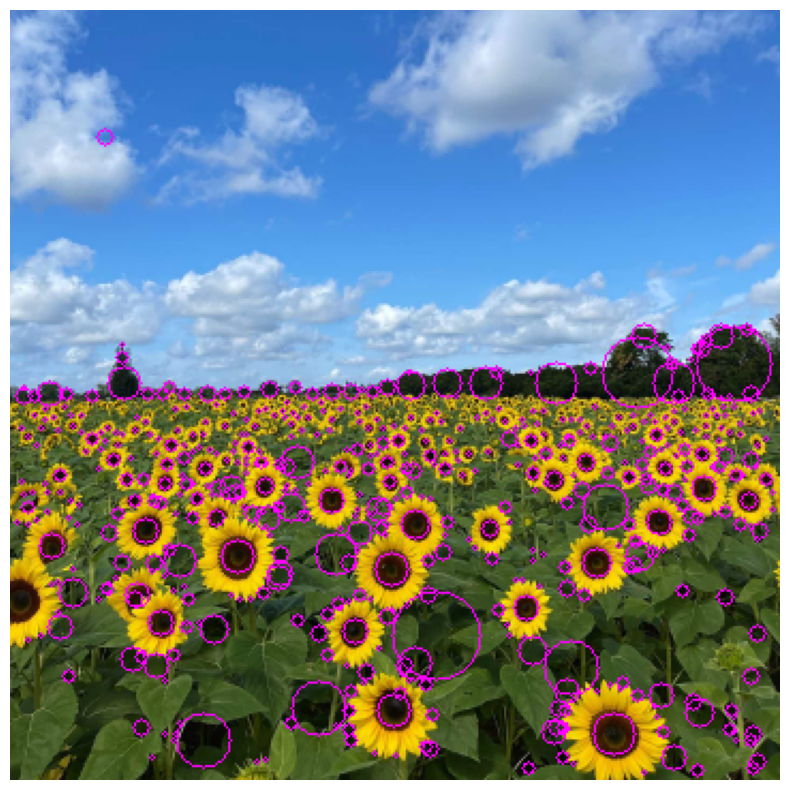

In [9]:
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [10]:
print('Largest circles: x, y, radius, sigma')
print(np.round(circles[:10, :4], 2))



Largest circles: x, y, radius, sigma
[[199.   292.    21.21  15.  ]
 [338.   165.    18.38  13.  ]
 [293.   169.    16.97  12.  ]
 [144.   326.    12.73   9.  ]
 [ 90.   341.    12.73   9.  ]
 [262.   307.    12.73   9.  ]
 [278.   232.    11.31   8.  ]
 [310.   174.     9.9    7.  ]
 [152.   254.     9.9    7.  ]
 [282.   338.     9.9    7.  ]]


Gaussian smoothing followed by the Laplacian approximates LoG filtering.
Multiplication by $\sigma^2$ normalizes the response across scales.
The search uses sigma values from 1 to 24 ..
A maximum is compared with its neighbours in position and scale. Equal maxima may both survive.
The threshold is 8 percent of the largest squared response and is selected for this image.
Positive responses select dark centres, the estimated radius is $r=\sqrt{2}\sigma$.
Coordinates and radii refer to the reduced image. Multiply them by four for approximate original-image values.
LoG can also select dark background structures. No additional colour filter is used.

Question 2

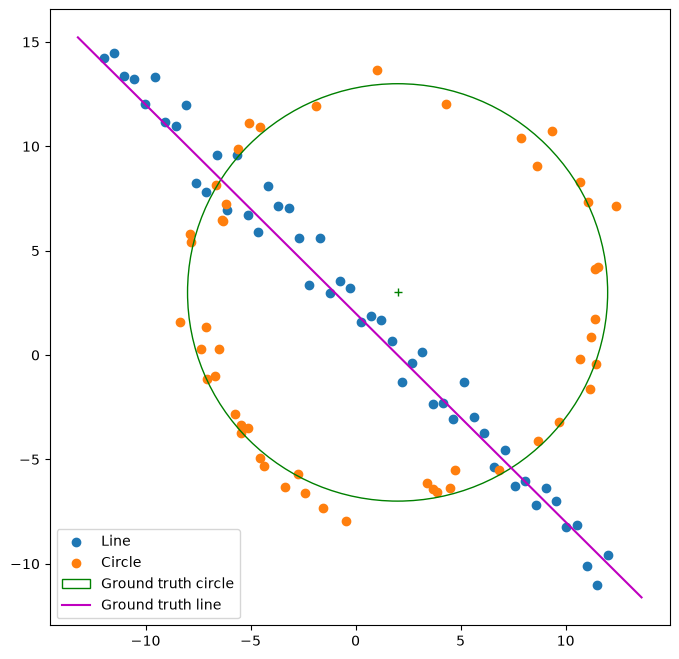

In [11]:
#---------------copied from en3160_assignment_02.pdf------------------
# Generation of a Noisy Point Set Conforming to a Line and a Circle
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3 # Center
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line)) # All points
#--------------------------------------

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()


In [16]:
X

array([[ -6.51668467,   0.30278774],
       [ -0.43437105,  -7.95194335],
       [ -5.73249084,  -2.82575284],
       [ -7.34200103,   0.29333185],
       [ -6.17674937,   7.25369394],
       [ -4.3802532 ,  -5.32148592],
       [ -6.30877504,   6.43627445],
       [  9.67227519,  -3.2044032 ],
       [ 11.19535174,   0.86332008],
       [ -5.61580776,   9.84793599],
       [  4.50899099,  -6.34996378],
       [ -7.10987876,   1.32766754],
       [ -7.08387069,  -1.13900056],
       [ 11.16600473,  -1.6271128 ],
       [ 11.05786244,   7.33454976],
       [ 10.69996536,   8.30351199],
       [ 11.52616119,   4.21671705],
       [  6.84865088,  -5.4857362 ],
       [  3.6859591 ,  -6.43018707],
       [  8.69218303,  -4.12536112],
       [ 11.40625583,   1.72865949],
       [  4.71186858,  -5.49890104],
       [ -7.81618803,   5.42333991],
       [  3.85858914,  -6.57008059],
       [  8.6132303 ,   9.07666108],
       [ -4.56254108,  -4.92473923],
       [  7.85832194,  10.39326675],
 

In [ ]:
from matplotlib.patheffects import Normal

#ax+ by = d
def line_from_points(points):
    vx, vy, x0, y0 = cv.fitLine(points.astype(np.float32), cv.DIST_L2, 0, 0.01, 0.01).ravel()
    #VX VY line direction
    #X0 Y0 A POINT ON THE LINE

    a = -vy
    b = vx

    #(a, b) is perpendicular to the line
    
    #MAKE DIRECTION PERPENDICULAR LINE
    # Along line     ( 0.707, 0.707)
    # Normal to line (-0.707, 0.707)

    length = np.hypot(a, b)
    a = a / length
    b = b / length

    #abs(a*x + b*y - d) GIVES PERPENDICLAR DISTANCE TO LINE
    #AT X0 Y0 ITS ZERO SO d IS,
    d = a*x0 + b*y0
    return np.array([a, b, d])


In [13]:
line_threshold = 1.5
line_consensus = 40
iterations = 1000
best_count = 0
best_error = np.inf
best_sample_line = None
best_inliers_line = None
np.random.seed(1)


In [ ]:
#---------algorithm taken from lec slides--------------
# L05 slides 24-37
for iteration in range(iterations):
    indices = np.random.choice(len(X), 2, replace=False)
    sample = X[indices]
    if np.allclose(sample[0], sample[1]):
        continue
    model = line_from_points(sample)
    a, b, d = model
    error = np.abs(a*X[:, 0] + b*X[:, 1] - d)
    inliers = error < line_threshold
    count = int(inliers.sum())
    if count < line_consensus:
        continue
    mean_error = np.mean(error[inliers] ** 2)
    better = count > best_count
    if count == best_count and mean_error < best_error:
        better = True
    if better:
        best_count = count
        best_error = mean_error
        best_sample_line = sample.copy()
        sample_model_line = model.copy()
        best_inliers_line = inliers.copy()
#--------------------------------------------------------
assert best_inliers_line is not None, 'No line consensus found'


In [ ]:
X_ = X[best_inliers_line]
best_model_line = line_from_points(X_)
if best_model_line[2] < 0:  #MAKING SURE if  D  NEGAATIVE, d is positive
    best_model_line = -best_model_line
print('Line [a, b, d]:', best_model_line)
print('Normal length:', np.linalg.norm(best_model_line[:2]))
print('Consensus size:', best_count)
print('Distance threshold:', line_threshold)


Line [a, b, d]: [0.71814156 0.69589704 1.5222032 ]
Normal length: 1.0
Consensus size: 56
Distance threshold: 1.5


RANSAC is implemented explicitly as required.
The built-in line fit uses squared perpendicular distances; the normal satisfies $a^2+b^2=1$.
The RANSAC error is $|ax+by-d|$ and the threshold is 1.5.
At least 40 of the 100 points must agree with a line.
The largest consensus is selected; cv.fitLine refits the line to those points.
The code uses 1000 trials.

2(b)

In [18]:
X_remaining = X[~best_inliers_line]
circle_threshold = 1.25
circle_consensus = 30

def circle_error(model, points):
    x0, y0, radius = model
    distance = np.sqrt((points[:, 0] - x0)**2 + (points[:, 1] - y0)**2)
    return distance - radius

def circle_cost(model, points):
    error = circle_error(model, points)
    return np.sum(error**2)


In [ ]:
# Circle through three points
def circle_from_points(sample):
    x1, y1 = sample[0]
    x2, y2 = sample[1]
    x3, y3 = sample[2]

    A = 2 * np.array([[x2 - x1, y2 - y1], [x3 - x1, y3 - y1]])
    b = np.array([x2**2 + y2**2 - x1**2 - y1**2,
                  x3**2 + y3**2 - x1**2 - y1**2])
    if abs(np.linalg.det(A)) < 1e-10:  # avoid collinear points
        return None
    
    x0, y0 = np.linalg.solve(A, b)
    radius = np.sqrt((x1 - x0)**2 + (y1 - y0)**2)
    return np.array([x0, y0, radius])


In [ ]:
#---------algorithm  from lec slides--------------

def circle_ransac(points, threshold, min_count, iterations):
    best_count = 0
    best_error = np.inf
    result = None

    for iteration in range(iterations):
        indices = np.random.choice(len(points), 3, replace=False)
        sample = points[indices]
        model = circle_from_points(sample)
        if model is None:
            continue
        error = np.abs(circle_error(model, points))
        inliers = error < threshold

        count = int(inliers.sum())

        if count < min_count:
            continue

        mean_error = np.mean(error[inliers]**2)
        better = count > best_count
        if count == best_count and mean_error < best_error:
            better = True
        if better:
            best_count = count
            best_error = mean_error
            result = (model.copy(), sample.copy(), inliers.copy())
    assert result is not None, 'No circle consensus found.'
    return result



In [ ]:
np.random.seed(2)
#best sample circle are the final 3 poinrs correctly giving circle
sample_model_circle, best_sample_circle, best_inliers_circle = circle_ransac(
    X_remaining, circle_threshold, circle_consensus, iterations)

circle_points = X_remaining[best_inliers_circle]

res = minimize(circle_cost, sample_model_circle, args=(circle_points,),
               method='L-BFGS-B', bounds=[(None, None), (None, None), (0.001, None)])
#method is Built-in optimizer supporting bounds
#radius atleat 0.001
assert res.success, res.message
best_model_circle = res.x
print('Circle [x, y, r]:', best_model_circle)
print('Consensus size:', len(circle_points))
print('Radial threshold:', circle_threshold)
print('Remaining points:', len(X_remaining))


Circle [x, y, r]: [1.86949347 3.12512284 9.93028444]
Consensus size: 43
Radial threshold: 1.25
Remaining points: 44


In [23]:
best_sample_circle

array([[ 8.69218303, -4.12536112],
       [11.05786244,  7.33454976],
       [ 3.85858914, -6.57008059]])

Circle RANSAC uses three-point samples and is implemented explicitly.
The error is $|\sqrt{(x-x_0)^2+(y-y_0)^2}-r|$.
The threshold 1.25 is twice the radial noise standard deviation of 0.625.
At least 30 remaining points must agree with the circle.
scipy.optimize.minimize refits the circle by minimizing squared radial errors.
The code uses 1000 trials.